Just Test(Environment Check)

In [18]:
from rdkit import Chem
print(Chem.MolFromSmiles("CCO"))

imports

In [1]:
import pandas as pd
from rdkit import Chem, DataStructs
from rdkit.Chem import Draw
from pathlib import Path
from rdkit.Chem import rdFingerprintGenerator
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
import seaborn as sns
from rdkit.Chem import Descriptors



no max on rows and columns display

In [22]:
pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)

# Optional: Prevent wide tables from wrapping onto multiple lines in terminals
pd.set_option("display.width", None)


In [2]:

# creating the sample data frame
data = {
   'name': ['omeprazole', 'aspirin', 'diazepam', 'ibuprofen', "amoxicillin", 'acetaminophen', 'levothyroxine'],
   'SMILES': ['CC1=CN=C(C(=C1OC)C)CS(=O)C2=NC3=C(N2)C=C(C=C3)OC', 'CC(=O)OC1=CC=CC=C1C(=O)O', 'CN1C(=O)CN=C(C2=C1C=CC(=C2)Cl)C3=CC=CC=C3', 'CC(C)CC1=CC=C(C=C1)C(C)C(=O)O', 'C[C@@]1([C@@H](N2[C@H](S1(=O)=O)CC2=O)C(=O)[O-])CCl.CC1([C@@H](N2[C@H](S1)[C@@H](C2=O)NC(=O)[C@@H](C3=CC=C(C=C3)O)N)C(=O)O)C.[K+]', 'CC(=O)NC1=CC=C(C=C1)O', 'C1=C(C=C(C(=C1I)OC2=CC(=C(C(=C2)I)O)I)I)C[C@@H](C(=O)O)N']
 }
df = pd.DataFrame(data)
#print(df)

#cobverting the SMILES to molecules using rdkit's molFromSmiles function

mols = [Chem.MolFromSmiles(s) for s in df['SMILES']]

#generating the grif image

#img = Draw.MolsToGridImage(mols, molsPerRow = 3, subImgSize = (200, 200), legends = df['name'].tolist(),
#                          returnPNG = True,
#                           )

#saving the image to a file

#with open('molecules.png', 'wb') as file:
    #file.write(img.data)


Saving Image


`MolsToGridImage` returns an IPython display object in a notebook, not a PIL
image, so there is no `.save()`. The PNG bytes live in `.data`, so write those
directly. With `useSVG=True` the `.data` is SVG text instead, and you'd write
it as text to a `.svg` file.


In [6]:
"""out_dir = Path("output")
out_dir.mkdir(exist_ok=True)

with open(out_dir / "molecules.png", 'wb') as file:
    file.write(img.data)"""

'out_dir = Path("output")\nout_dir.mkdir(exist_ok=True)\n\nwith open(out_dir / "molecules.png", \'wb\') as file:\n    file.write(img.data)'

Working with the SMILES using morgan fingerprint and checking the similarities using tanimoto


In [7]:
# initializing the Morgan Generator (ECFP4)

mfpgen = rdFingerprintGenerator.GetMorganGenerator(radius = 2, fpSize = 2048)

#generating fingerprints as a bit vector

fp = [mfpgen.GetFingerprint(mol) for mol in mols]

# calculating the similarity between the first molecule and all other molecules in the list using tonimoto

similarities = DataStructs.BulkTanimotoSimilarity(fp[0], fp) 

# Adding the similarity values to the data frame

df['similarity_to_mol_0'] = similarities

#print(df[["SMILES", "similarity_to_mol_0"]])

compare against every other molecule


In [8]:
n = len(fp)
sim_matrix = np.zeros((n,n))

#compute similarity row by row
for i in range(n):
    sim_matrix[i,:] = DataStructs.BulkTanimotoSimilarity(fp[i], fp)

#display as a clean df
sim_df = pd.DataFrame(sim_matrix, columns = df['name'], index = df['name'])
print(sim_df)

name           omeprazole   aspirin  diazepam  ibuprofen  amoxicillin  \
name                                                                    
omeprazole       1.000000  0.090909  0.088608   0.089552     0.071429   
aspirin          0.090909  1.000000  0.148148   0.195122     0.090909   
diazepam         0.088608  0.148148  1.000000   0.105263     0.111111   
ibuprofen        0.089552  0.195122  0.105263   1.000000     0.141176   
amoxicillin      0.071429  0.090909  0.111111   0.141176     1.000000   
acetaminophen    0.079365  0.222222  0.115385   0.184211     0.150000   
levothyroxine    0.120000  0.176471  0.088235   0.244898     0.136842   

name           acetaminophen  levothyroxine  
name                                         
omeprazole          0.079365       0.120000  
aspirin             0.222222       0.176471  
diazepam            0.115385       0.088235  
ibuprofen           0.184211       0.244898  
amoxicillin         0.150000       0.136842  
acetaminophen       

Visualizing using heatmaps
since the data frame is already created, we just use imshow

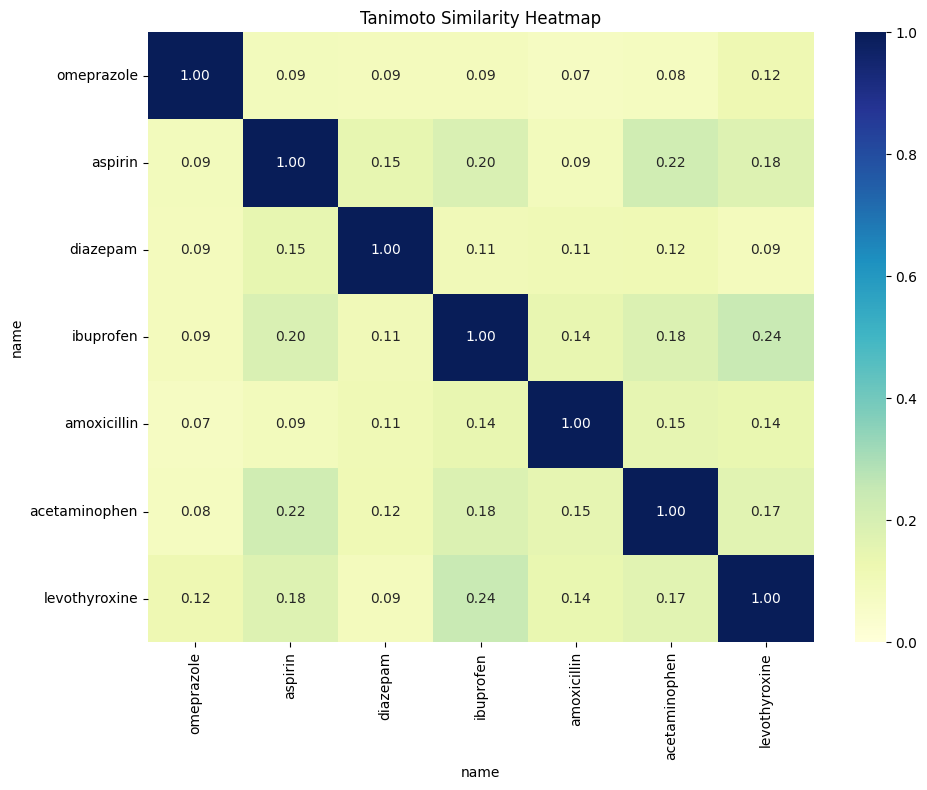

In [9]:
plt.figure(figsize = (10, 8))
sns.heatmap(sim_df, xticklabels = sim_df.columns, yticklabels = sim_df.index, annot = True, fmt = ".2f", cmap = "YlGnBu", vmin = 0, vmax = 1)
plt.title("Tanimoto Similarity Heatmap")
plt.tight_layout()
plt.show()


Computing Molecular Weight and LogP 

In [24]:
df["mols"] = df["SMILES"].apply(lambda s: Chem.MolFromSmiles(s) if pd.notnull(s) else None)

df["molWt"] = df["mols"].apply(lambda m: Descriptors.MolWt(m) if m is not None else None)
df["LogP"] = df["mols"].apply(lambda m: Descriptors.MolLogP(m) if m is not None else None)

print(df[["SMILES", "molWt", "LogP"]])

                                              SMILES    molWt     LogP
0   CC1=CN=C(C(=C1OC)C)CS(=O)C2=NC3=C(N2)C=C(C=C3)OC  345.424  2.89974
1                           CC(=O)OC1=CC=CC=C1C(=O)O  180.159  1.31010
2          CN1C(=O)CN=C(C2=C1C=CC(=C2)Cl)C3=CC=CC=C3  284.746  3.15380
3                      CC(C)CC1=CC=C(C=C1)C(C)C(=O)O  206.285  3.07320
4  C[C@@]1([C@@H](N2[C@H](S1(=O)=O)CC2=O)C(=O)[O-...  671.191 -4.88310
5                              CC(=O)NC1=CC=C(C=C1)O  151.165  1.35060
6  C1=C(C=C(C(=C1I)OC2=CC(=C(C(=C2)I)O)I)I)C[C@@H...  776.872  4.55730


Scatter plot for MW vs logP (With Lipinkski bounbdaries)

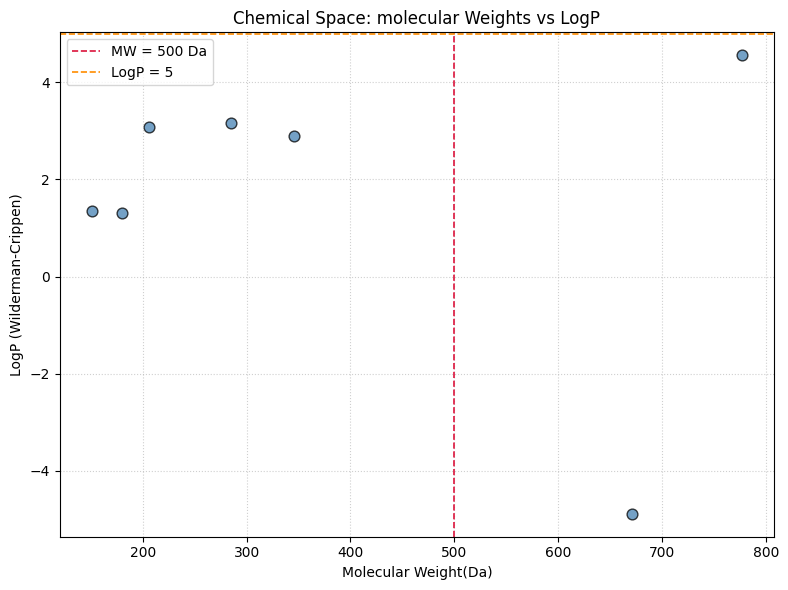

In [26]:
plt.figure(figsize=(8, 6))

#creating the scatter plot
plt.scatter(df["molWt"], df["LogP"], alpha = 0.75, edgecolors="k", s=60, color="steelblue")

#9optional) adding dash reference lines for lipinski rule of 5 thresholds

plt.axvline(x=500, color="crimson", linestyle="--", linewidth=1.2, label="MW = 500 Da")
plt.axhline(y=5, color="darkorange", linestyle="--", linewidth=1.2, label="LogP = 5")

#labels and formatting
plt.title("Chemical Space: molecular Weights vs LogP")
plt.xlabel("Molecular Weight(Da)")
plt.ylabel("LogP (Wilderman-Crippen)")
plt.grid(True, linestyle=":", alpha = 0.6)
plt.legend()
plt.tight_layout()
plt.show()

Colouring the points by tanimoto Similarity

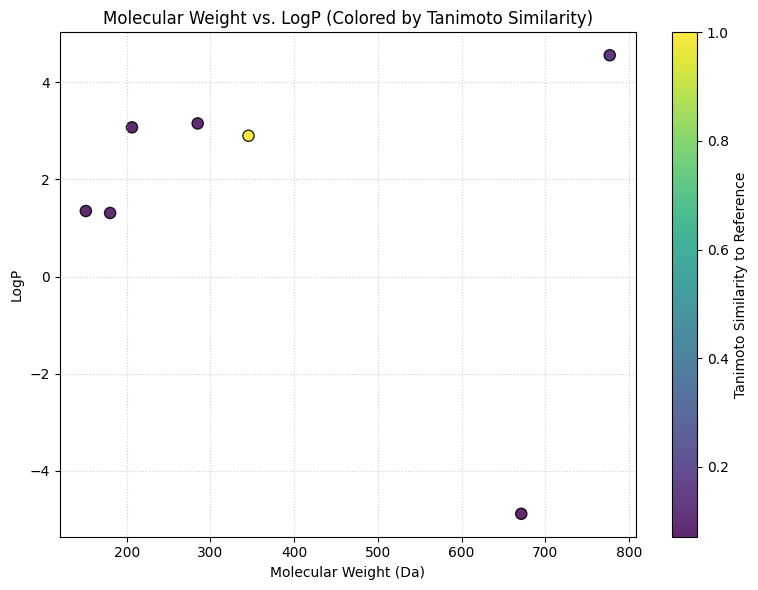

In [28]:
plt.figure(figsize=(8, 6))

scatter = plt.scatter(
    df["molWt"],
    df["LogP"],
    c=df["similarity_to_mol_0"],  # Color by Tanimoto similarity
    cmap="viridis",
    alpha=0.85,
    edgecolors="k",
    s=65,
)

plt.colorbar(scatter, label="Tanimoto Similarity to Reference")
plt.title("Molecular Weight vs. LogP (Colored by Tanimoto Similarity)")
plt.xlabel("Molecular Weight (Da)")
plt.ylabel("LogP")
plt.grid(True, linestyle=":", alpha=0.6)
plt.tight_layout()
plt.show()
